# Experiment 2 — Neighborhood signal audit

**Question.** What information surrounds a target flow in the original 30-second host graph, and does label-free neighborhood context add predictive value beyond the target flow and its endpoints' own prior activity?

Run all cells in Google Colab. This notebook reads the original Wednesday train/validation/Test 1 graphs and Thursday Test 2 graphs in chronological order. It does not retrain a GNN. The original binary label is `Attack == "Infilteration"`; it does not identify lateral movement or compromise. Test 2 results here are descriptive and exploratory. All modeling choices below are fixed before looking at Test 1 or Test 2 labels.

**Time definitions.** Snapshot metrics use the complete flow-start window and are retrospective. `prior_window_*` features use graph windows with an earlier start, but those flows may not have completed. A separate audited raw CSV join is required before any `causal_*` field is produced. A zero exporter delay is assumed for that completion-time analysis. Neither set of retrospective graph features establishes online latency.


## 1. Configure Colab and provenance

Change only the Drive root if your files live elsewhere. Outputs go to a new, timestamped folder. This run needs enough Drive space for per-flow Parquet files and enough RAM to load one day's compact event table. Graphs and raw CSVs are read only.


In [1]:
import hashlib
import importlib.util
import json
import os
import re
import subprocess
import sys
from collections import Counter, defaultdict
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score

if importlib.util.find_spec('torch_geometric') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'torch_geometric'], check=True)
if importlib.util.find_spec('pyarrow') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pyarrow'], check=True)
import pyarrow as pa
import pyarrow.parquet as pq
import torch
from google.colab import drive

drive.mount('/content/drive')
DRIVE_ROOT = Path('/content/drive/MyDrive/nids-mitre')
WED_ROOT = DRIVE_ROOT / 'dataset_processed'
THU_ROOT = DRIVE_ROOT / 'dataset_processed_thu0103'
RAW_CSV = {
    'wed': DRIVE_ROOT / 'data/cicids2018-v3/cicids2018v3_wed2802.csv',
    'thu': DRIVE_ROOT / 'data/cicids2018-v3/cicids2018v3_thu0103.csv',
}
SCALER_PATH = WED_ROOT / 'scaler_wed2802.pkl'
OUTPUT_ROOT = DRIVE_ROOT / 'results_comparison' / 'graph_neighborhood_audit_v1'
RUN_DIR = OUTPUT_ROOT / datetime.now(timezone.utc).strftime('run_%Y%m%dT%H%M%SZ')
RUN_DIR.mkdir(parents=True, exist_ok=False)
WINDOW_SECONDS = 30
EXPECTED_TEST2_FLOWS = 2_135_957
EXPECTED_TEST2_POSITIVES = 103_825

# Record the graph-builder code used as the documented preprocessing reference.
PREPROCESSING_REFERENCE = 'cic_ids2018_v3_graph_creation.ipynb / cic_ids2018_v3_graph_creation_TEST2.ipynb'
GRAPH_VERSION = 'original 30-second flow-start host multigraph; original Infilteration labels'
print('Output:', RUN_DIR)
print('PyTorch:', torch.__version__, '| pandas:', pd.__version__)


Mounted at /content/drive
Output: /content/drive/MyDrive/nids-mitre/results_comparison/graph_neighborhood_audit_v1/run_20261022T142050Z
PyTorch: 2.11.0+cpu | pandas: 2.2.3


## 2. Snapshot topology and endpoint history

A flow is identified by `(day, window_id, edge_index_within_graph)`. Wednesday IP IDs persist through its three splits; Thursday has a separate IP-to-ID map. The graph files are read in chronological order, including empty windows. Directed reachability counts distinct nodes reachable in one or at most two hops, excluding the starting node. Component size is weakly connected component size of the full window multigraph. Parallel-edge count uses the directed `(source, destination)` pair and includes the target; `other_parallel_edges` subtracts it.

Current-window label fractions and previous-window label fractions are **diagnostics only**. Their denominators exclude the target edge. No label-derived column enters the baseline.


In [2]:
def sha256_file(path, block_size=8 * 1024 * 1024):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(block_size), b''):
            h.update(block)
    return h.hexdigest()


def graph_inventory(root, splits):
    records = []
    for split in splits:
        for path in (root / split).glob('graph_*.pt'):
            match = re.fullmatch(r'graph_(\d+)\.pt', path.name)
            assert match, path
            records.append((int(match.group(1)), split, path))
    records.sort(key=lambda r: r[0])
    ids = [r[0] for r in records]
    assert ids == list(range(len(ids))), f'Nonconsecutive graph IDs in {root}'
    return records

INVENTORY = {
    'wed': graph_inventory(WED_ROOT, ['train', 'val', 'test']),
    'thu': graph_inventory(THU_ROOT, ['test2']),
}
assert len(INVENTORY['thu']) == 2_822, len(INVENTORY['thu'])
for day, records in INVENTORY.items():
    assert records, day
    print(day, 'graphs:', len(records), 'splits:', Counter(x[1] for x in records))


def component_sizes(n, src, dst):
    parent = list(range(n))
    size = [1] * n
    def find(v):
        while parent[v] != v:
            parent[v] = parent[parent[v]]
            v = parent[v]
        return v
    for a, b in zip(src, dst):
        ra, rb = find(int(a)), find(int(b))
        if ra != rb:
            if size[ra] < size[rb]:
                ra, rb = rb, ra
            parent[rb] = ra
            size[ra] += size[rb]
    return np.array([size[find(v)] for v in range(n)], dtype=np.int32)


def reach_counts(out_neighbors):
    one = np.zeros(len(out_neighbors), dtype=np.int32)
    two = np.zeros(len(out_neighbors), dtype=np.int32)
    for v, direct in enumerate(out_neighbors):
        first = direct - {v}
        reached = set(first)
        for peer in direct:
            reached.update(out_neighbors[peer])
        reached.discard(v)
        one[v] = len(first)
        two[v] = len(reached)
    return one, two


def make_history():
    return dict(seen_windows=Counter(), last_window={}, incident=Counter(),
                outgoing=Counter(), incoming=Counter(), out_positive=Counter(),
                in_positive=Counter(), out_peers=defaultdict(set),
                in_peers=defaultdict(set))


def snapshot_frame(graph, day, split, window_id, hist):
    src_local = graph.edge_index[0].cpu().numpy().astype(np.int32)
    dst_local = graph.edge_index[1].cpu().numpy().astype(np.int32)
    y = graph.y.cpu().numpy().astype(np.int8)
    attr = graph.edge_attr.cpu().numpy().astype(np.float32)
    gids = graph.global_node_ids.cpu().numpy().astype(np.int64)
    n, m = len(gids), len(y)
    assert graph.edge_index.shape == (2, m) and attr.shape[0] == m
    assert n == int(graph.num_nodes) and len(np.unique(gids)) == n
    if m == 0:
        assert n == 0
        return None, {'day': day, 'split': split, 'window_id': window_id,
                      'edges': 0, 'nodes': 0, 'positive_edges': 0,
                      'max_out_degree': 0, 'max_component_size': 0}
    assert src_local.min() >= 0 and dst_local.min() >= 0
    assert src_local.max() < n and dst_local.max() < n
    assert np.isin(y, [0, 1]).all()
    src = gids[src_local]
    dst = gids[dst_local]
    out_degree = np.bincount(src_local, minlength=n)
    in_degree = np.bincount(dst_local, minlength=n)
    out_pos = np.bincount(src_local, weights=y, minlength=n).astype(np.int32)
    in_pos = np.bincount(dst_local, weights=y, minlength=n).astype(np.int32)
    out_peers = [set() for _ in range(n)]
    in_peers = [set() for _ in range(n)]
    for a, b in zip(src_local, dst_local):
        out_peers[a].add(int(b))
        in_peers[b].add(int(a))
    comp = component_sizes(n, src_local, dst_local)
    one, two = reach_counts(out_peers)
    pairs = Counter(zip(src.tolist(), dst.tolist()))
    self_loops = np.bincount(src_local[src_local == dst_local], minlength=n)
    incident_degree = out_degree + in_degree - self_loops
    other_incident = np.fromiter((
        int(incident_degree[a]) - 1 if a == b else
        int(incident_degree[a] + incident_degree[b]
            - pairs[(int(gids[a]), int(gids[b]))]
            - pairs[(int(gids[b]), int(gids[a]))] - 1)
        for a, b in zip(src_local, dst_local)
    ), dtype=np.int32, count=m)
    assert (other_incident >= 0).all()
    last = hist['last_window']
    seen = hist['seen_windows']
    incident = hist['incident']
    previous_out = hist['outgoing']
    previous_in = hist['incoming']
    previous_out_pos = hist['out_positive']
    previous_in_pos = hist['in_positive']
    prior_out_peers = hist['out_peers']
    prior_in_peers = hist['in_peers']

    def node_value(values, ids):
        return np.fromiter((values[int(v)] for v in ids), dtype=np.int32, count=m)
    def lag(ids):
        return np.fromiter((window_id - last[int(v)] if int(v) in last else -1
                            for v in ids), dtype=np.int32, count=m)
    def peer_activity(peer_map, ids):
        return np.fromiter((sum(incident[p] for p in peer_map[int(v)] if p != int(v))
                            for v in ids), dtype=np.int32, count=m)
    def peer_reach(peer_map, ids):
        return np.fromiter((len(peer_map[int(v)] - {int(v)}) for v in ids),
                           dtype=np.int32, count=m)

    frame = pd.DataFrame({
        'day': day, 'split': split, 'window_id': np.int32(window_id),
        'edge_index_within_graph': np.arange(m, dtype=np.int32),
        'source_gid': src, 'destination_gid': dst, 'label': y,
        'snapshot_src_in_degree': in_degree[src_local].astype(np.int32),
        'snapshot_src_out_degree': out_degree[src_local].astype(np.int32),
        'snapshot_dst_in_degree': in_degree[dst_local].astype(np.int32),
        'snapshot_dst_out_degree': out_degree[dst_local].astype(np.int32),
        'snapshot_src_distinct_out_peers': [len(out_peers[v]) for v in src_local],
        'snapshot_src_distinct_in_peers': [len(in_peers[v]) for v in src_local],
        'snapshot_dst_distinct_out_peers': [len(out_peers[v]) for v in dst_local],
        'snapshot_dst_distinct_in_peers': [len(in_peers[v]) for v in dst_local],
        'snapshot_parallel_edges': [pairs[(int(a), int(b))] for a, b in zip(src, dst)],
        'snapshot_other_incident_edges': other_incident,
        'snapshot_src_component_size': comp[src_local],
        'snapshot_dst_component_size': comp[dst_local],
        'snapshot_src_reach_1hop': one[src_local],
        'snapshot_src_reach_2hop': two[src_local],
        'snapshot_dst_reach_1hop': one[dst_local],
        'snapshot_dst_reach_2hop': two[dst_local],
        'prior_window_src_appearances': node_value(seen, src),
        'prior_window_dst_appearances': node_value(seen, dst),
        'prior_window_src_gap_windows': lag(src),
        'prior_window_dst_gap_windows': lag(dst),
        'prior_window_src_incident_edges': node_value(incident, src),
        'prior_window_dst_incident_edges': node_value(incident, dst),
        'prior_window_src_out_edges': node_value(previous_out, src),
        'prior_window_dst_in_edges': node_value(previous_in, dst),
        'prior_window_src_distinct_out_peers': peer_reach(prior_out_peers, src),
        'prior_window_dst_distinct_in_peers': peer_reach(prior_in_peers, dst),
        'prior_window_src_peer_activity': peer_activity(prior_out_peers, src),
        'prior_window_dst_peer_activity': peer_activity(prior_in_peers, dst),
        'diag_current_shared_src_other_edges': (out_degree[src_local] - 1).astype(np.int32),
        'diag_current_shared_dst_other_edges': (in_degree[dst_local] - 1).astype(np.int32),
        'diag_current_shared_src_other_positive': (out_pos[src_local] - y).astype(np.int32),
        'diag_current_shared_dst_other_positive': (in_pos[dst_local] - y).astype(np.int32),
        'diag_past_shared_src_edges': node_value(previous_out, src),
        'diag_past_shared_dst_edges': node_value(previous_in, dst),
        'diag_past_shared_src_positive': node_value(previous_out_pos, src),
        'diag_past_shared_dst_positive': node_value(previous_in_pos, dst),
    })
    frame['snapshot_other_parallel_edges'] = frame['snapshot_parallel_edges'] - 1
    for role, time in [('src', 'current'), ('dst', 'current'),
                       ('src', 'past'), ('dst', 'past')]:
        denom = frame[f'diag_{time}_shared_{role}_other_edges'] if time == 'current' else frame[f'diag_{time}_shared_{role}_edges']
        numerator = frame[f'diag_{time}_shared_{role}_other_positive'] if time == 'current' else frame[f'diag_{time}_shared_{role}_positive']
        frame[f'diag_{time}_shared_{role}_positive_fraction'] = np.divide(
            numerator.to_numpy(), denom.to_numpy(),
            out=np.full(m, np.nan, dtype=np.float32), where=denom.to_numpy() > 0)
    frame['snapshot_only_target_context'] = frame.snapshot_other_incident_edges == 0
    frame['prior_window_no_incident_edges'] = (
        (frame.prior_window_src_incident_edges == 0) &
        (frame.prior_window_dst_incident_edges == 0)
    )
    for k in range(attr.shape[1]):
        frame[f'attr_{k:02d}'] = attr[:, k]

    # Update only after all edges in this window have been characterized.
    for a, b, label in zip(src, dst, y):
        a, b, label = int(a), int(b), int(label)
        incident[a] += 1
        if b != a:
            incident[b] += 1
        previous_out[a] += 1
        previous_in[b] += 1
        previous_out_pos[a] += label
        previous_in_pos[b] += label
        prior_out_peers[a].add(b)
        prior_in_peers[b].add(a)
    for v in gids:
        v = int(v)
        seen[v] += 1
        last[v] = window_id
    window_record = {
        'day': day, 'split': split, 'window_id': window_id,
        'edges': m, 'nodes': n, 'positive_edges': int(y.sum()),
        'max_out_degree': int(out_degree.max()),
        'max_component_size': int(comp.max()),
        'median_out_degree': float(np.median(out_degree)),
        'median_component_size': float(np.median(comp)),
        'edges_with_other_parallel': int((frame.snapshot_other_parallel_edges > 0).sum()),
        'edges_with_current_other_incident': int((~frame.snapshot_only_target_context).sum()),
    }
    return frame, window_record


def write_parts(parts, destination, serial):
    if parts:
        destination.mkdir(parents=True, exist_ok=True)
        pd.concat(parts, ignore_index=True).to_parquet(
            destination / f'part_{serial:05d}.parquet', index=False)
        parts.clear()
        return serial + 1
    return serial

window_rows = []
snapshot_totals = {}
for day, records in INVENTORY.items():
    history = make_history()
    parts, serial, edges_by_split = [], 0, Counter()
    first_time = None
    for i, (window_id, split, path) in enumerate(records):
        graph = torch.load(path, map_location='cpu', weights_only=False)
        graph_time = pd.Timestamp(graph.timestamp)
        if first_time is None:
            first_time = graph_time
        assert graph_time == first_time + pd.Timedelta(seconds=WINDOW_SECONDS * window_id)
        frame, record = snapshot_frame(graph, day, split, window_id, history)
        record['graph_sha256'] = sha256_file(path)
        window_rows.append(record)
        edges_by_split[split] += record['edges']
        if frame is not None:
            parts.append(frame)
        if len(parts) >= 50:
            serial = write_parts(parts, RUN_DIR / 'snapshot' / day, serial)
        if (i + 1) % 500 == 0:
            print(day, 'graphs read:', i + 1)
    serial = write_parts(parts, RUN_DIR / 'snapshot' / day, serial)
    snapshot_totals[day] = dict(edges_by_split)
    print(day, 'flow counts:', dict(edges_by_split))
window_table = pd.DataFrame(window_rows)
window_table.to_parquet(RUN_DIR / 'window_distributions.parquet', index=False)
assert sum(snapshot_totals['thu'].values()) == EXPECTED_TEST2_FLOWS
assert int(window_table.query("day == 'thu'").positive_edges.sum()) == EXPECTED_TEST2_POSITIVES
assert window_table.groupby(['day','split']).edges.sum().to_dict() == {
    (day, split): count for day, counts in snapshot_totals.items() for split, count in counts.items()
}
print('Every graph contributes its exact edge count; Test 2 counts match the audited originals.')


wed graphs: 2855 splits: Counter({'train': 1998, 'test': 429, 'val': 428})
thu graphs: 2822 splits: Counter({'test2': 2822})
wed graphs read: 500
wed graphs read: 1000
wed graphs read: 1500
wed graphs read: 2000
wed graphs read: 2500
wed flow counts: {'train': 1041793, 'val': 788535, 'test': 191679}
thu graphs read: 500
thu graphs read: 1000
thu graphs read: 1500
thu graphs read: 2000
thu graphs read: 2500
thu flow counts: {'test2': 2135957}
Every graph contributes its exact edge count; Test 2 counts match the audited originals.


## 3. Audit the raw-row join before completion-time analysis

The saved graphs do not carry raw row IDs. This cell reconstructs the graph builder's within-window CSV order and per-day IP-ID assignment, then checks every edge's endpoints, label, and all 32 encoded attributes against its raw row. This is stronger than matching on a nonunique five-tuple. A day passes only if every graph edge has exactly one reconstructed raw row and all checks pass. If a raw CSV or scaler is missing, or an assertion fails, the causal step is skipped; the snapshot outputs remain usable. The first mismatch is reported and no unmatched rows are silently accepted.


In [3]:
import joblib

NUMERIC_FEATURES = [
    'IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'OUT_PKTS',
    'FLOW_DURATION_MILLISECONDS', 'DURATION_IN', 'DURATION_OUT',
    'SRC_TO_DST_IAT_AVG', 'DST_TO_SRC_IAT_AVG',
    'SRC_TO_DST_IAT_STDDEV', 'DST_TO_SRC_IAT_STDDEV',
    'MIN_IP_PKT_LEN', 'MAX_IP_PKT_LEN',
    'RETRANSMITTED_IN_PKTS', 'RETRANSMITTED_OUT_PKTS',
    'TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT',
    'TCP_FLAGS', 'MIN_TTL', 'MAX_TTL',
]
RAW_COLUMNS = ['FLOW_START_TIME', 'FLOW_DURATION_MILLISECONDS',
               'IPV4_SRC_ADDR', 'IPV4_DST_ADDR', 'PROTOCOL', 'L4_DST_PORT',
               'Attack', *[c for c in NUMERIC_FEATURES if c != 'FLOW_DURATION_MILLISECONDS']]


def port_role(port):
    if port in (80, 443, 8080, 8443, 81, 3128, 8545): return 0
    if port in (22, 222, 2222, 23, 2323, 3389, 3390, 3394, 5900, 5901, 5555, 21, 2131): return 1
    if port in (445, 135, 137, 138, 139): return 2
    if port in (53, 5355, 67, 547, 123, 1900, 5060): return 3
    if port in (1433, 3306, 5432, 6379, 27017): return 4
    if port < 1024: return 5
    return 6


def protocol_role(proto):
    if proto == 6: return 0
    if proto == 17: return 1
    if proto in (1, 58): return 2
    if proto == 2: return 3
    return 4


def audit_raw_day(day):
    assert RAW_CSV[day].is_file(), f'Missing raw CSV: {RAW_CSV[day]}'
    assert SCALER_PATH.is_file(), f'Missing scaler: {SCALER_PATH}'
    scaler = joblib.load(SCALER_PATH)
    inventory = INVENTORY[day]
    graph_start = pd.Timestamp(torch.load(inventory[0][2], map_location='cpu', weights_only=False).timestamp)
    ip_map = {}
    next_id = 0
    joined_parts = []
    serial = 0
    checked_edges = 0
    checked_positive = 0
    seen_windows = set()
    last_completed_window = -1
    row_offset = 0
    pending = pd.DataFrame()

    def gid(ip):
        nonlocal next_id
        if ip not in ip_map:
            ip_map[ip] = next_id
            next_id += 1
        return ip_map[ip]

    def audit_group(window_id, group):
        nonlocal checked_edges, checked_positive, serial, last_completed_window
        window_id = int(window_id)
        assert window_id > last_completed_window, ('Raw CSV windows out of order', window_id, last_completed_window)
        assert window_id < len(inventory)
        _, split, graph_path = inventory[window_id]
        graph = torch.load(graph_path, map_location='cpu', weights_only=False)
        m = len(group)
        assert m == int(graph.y.numel()), ('Row count mismatch', day, window_id, m, int(graph.y.numel()))
        src = np.array([gid(v) for v in group.IPV4_SRC_ADDR], dtype=np.int64)
        dst = np.array([gid(v) for v in group.IPV4_DST_ADDR], dtype=np.int64)
        ids = graph.global_node_ids.cpu().numpy()
        saved_src = ids[graph.edge_index[0].cpu().numpy()]
        saved_dst = ids[graph.edge_index[1].cpu().numpy()]
        np.testing.assert_array_equal(src, saved_src, err_msg=f'{day} window {window_id} source IDs')
        np.testing.assert_array_equal(dst, saved_dst, err_msg=f'{day} window {window_id} destination IDs')
        labels = group.Attack.eq('Infilteration').to_numpy(dtype=np.int8)
        np.testing.assert_array_equal(labels, graph.y.cpu().numpy().astype(np.int8),
                                      err_msg=f'{day} window {window_id} labels')
        numeric = np.log1p(group[NUMERIC_FEATURES].to_numpy(dtype=np.float64))
        numeric = scaler.transform(numeric).astype(np.float32)
        ports = group.L4_DST_PORT.map(port_role).to_numpy(dtype=np.int64)
        protocols = group.PROTOCOL.map(protocol_role).to_numpy(dtype=np.int64)
        reconstructed = np.concatenate([np.eye(7, dtype=np.float32)[ports],
                                        np.eye(5, dtype=np.float32)[protocols], numeric], axis=1)
        np.testing.assert_allclose(reconstructed, graph.edge_attr.cpu().numpy(),
                                   rtol=2e-5, atol=2e-5,
                                   err_msg=f'{day} window {window_id} edge attributes')
        starts = group.FLOW_START_TIME
        durations = pd.to_numeric(group.FLOW_DURATION_MILLISECONDS, errors='coerce')
        assert starts.notna().all() and np.isfinite(durations.to_numpy()).all()
        assert (durations >= 0).all(), ('Invalid flow duration', day, window_id)
        ends = starts + pd.to_timedelta(durations, unit='ms')
        assert ends.notna().all()
        joined_parts.append(pd.DataFrame({
            'day': day, 'split': split, 'window_id': np.int32(window_id),
            'edge_index_within_graph': np.arange(m, dtype=np.int32),
            'raw_csv_row': group.raw_csv_row.to_numpy(dtype=np.int64),
            'source_gid': src, 'destination_gid': dst, 'label': labels,
            'flow_start_ns': starts.astype('int64').to_numpy(),
            'flow_end_ns': ends.astype('int64').to_numpy(),
        }))
        checked_edges += m
        checked_positive += int(labels.sum())
        seen_windows.add(window_id)
        last_completed_window = window_id
        if len(joined_parts) >= 100:
            serial = write_parts(joined_parts, RUN_DIR / 'raw_join' / day, serial)

    for chunk in pd.read_csv(RAW_CSV[day], usecols=RAW_COLUMNS, chunksize=250_000):
        chunk['raw_csv_row'] = np.arange(row_offset, row_offset + len(chunk), dtype=np.int64)
        row_offset += len(chunk)
        chunk = chunk.loc[(chunk.IPV4_SRC_ADDR != '0.0.0.0') &
                          (chunk.IPV4_DST_ADDR != '0.0.0.0')].copy()
        chunk['FLOW_START_TIME'] = pd.to_datetime(chunk.FLOW_START_TIME, errors='coerce')
        assert chunk.FLOW_START_TIME.notna().all(), 'Invalid raw start timestamp'
        combined = pd.concat([pending, chunk], ignore_index=True)
        if combined.empty:
            continue
        combined['window_id'] = ((combined.FLOW_START_TIME - graph_start) //
                                 pd.Timedelta(seconds=WINDOW_SECONDS)).astype(np.int32)
        assert (combined.window_id >= 0).all()
        last = int(combined.window_id.max())
        ready = combined.loc[combined.window_id < last]
        for window_id, group in ready.groupby('window_id', sort=True):
            audit_group(window_id, group)
        pending = combined.loc[combined.window_id == last].copy()
    if not pending.empty:
        for window_id, group in pending.groupby('window_id', sort=True):
            audit_group(window_id, group)
    serial = write_parts(joined_parts, RUN_DIR / 'raw_join' / day, serial)
    graph_edges = sum(int(torch.load(path, map_location='cpu', weights_only=False).y.numel())
                      for _, _, path in inventory)
    assert checked_edges == graph_edges, ('Missing raw rows', checked_edges, graph_edges)
    assert checked_positive == int(window_table.query('day == @day').positive_edges.sum())
    assert seen_windows == set(window_table.query('day == @day and edges > 0').window_id)
    result = {'day': day, 'status': 'PASS', 'raw_csv': str(RAW_CSV[day]),
              'raw_csv_sha256': sha256_file(RAW_CSV[day]),
              'scaler_sha256': sha256_file(SCALER_PATH),
              'checked_edges': checked_edges, 'checked_positive': checked_positive,
              'raw_csv_rows': row_offset, 'ip_ids_reconstructed': next_id}
    (RUN_DIR / f'raw_join_{day}_PASS.json').write_text(json.dumps(result, indent=2))
    return result

join_audit = {}
for day in ('wed', 'thu'):
    try:
        join_audit[day] = audit_raw_day(day)
        print(day, 'raw join: PASS', join_audit[day]['checked_edges'], 'flows')
    except Exception as exc:
        join_audit[day] = {'day': day, 'status': 'FAIL', 'reason': repr(exc)}
        print(day, 'raw join: FAIL; causal analysis for this day is deferred.', repr(exc))
(RUN_DIR / 'raw_join_audit.json').write_text(json.dumps(join_audit, indent=2))


wed raw join: PASS 2022007 flows
thu raw join: PASS 2135957 flows


913

## 4. Strictly prior, already completed context

For a target flow, the query time is its recorded end. Only other flows with `end < target.end` enter the causal graph. Equal-end-time flows are withheld together, so the target cannot enter its own context. Directed degree, distinct peers, weak component size, and one/two-hop reachability are measured on that prior completed graph. The event sweep uses the audited row join and resets at the day boundary. Label fractions here remain diagnostic and are never model features. This zero-delay analysis is optimistic because exporter delay is unknown.


In [4]:
def read_parts(folder, columns=None):
    files = sorted(folder.glob('part_*.parquet'))
    assert files, f'No Parquet parts: {folder}'
    return pd.concat((pd.read_parquet(p, columns=columns) for p in files), ignore_index=True)


def causal_day(day):
    assert join_audit[day]['status'] == 'PASS'
    columns = ['day', 'split', 'window_id', 'edge_index_within_graph',
               'raw_csv_row', 'source_gid', 'destination_gid', 'label',
               'flow_start_ns', 'flow_end_ns']
    joined = read_parts(RUN_DIR / 'raw_join' / day, columns)
    assert len(joined) == join_audit[day]['checked_edges']
    assert not joined.duplicated(['day', 'window_id', 'edge_index_within_graph']).any()
    assert not joined.raw_csv_row.duplicated().any()
    order = np.argsort(joined.flow_end_ns.to_numpy(), kind='stable')
    src = joined.source_gid.to_numpy(dtype=np.int64)
    dst = joined.destination_gid.to_numpy(dtype=np.int64)
    y = joined.label.to_numpy(dtype=np.int8)
    ends = joined.flow_end_ns.to_numpy(dtype=np.int64)
    n = len(joined)
    feature_names = [
        'causal_src_in_degree', 'causal_src_out_degree',
        'causal_dst_in_degree', 'causal_dst_out_degree',
        'causal_src_distinct_out_peers', 'causal_dst_distinct_in_peers',
        'causal_src_component_size', 'causal_dst_component_size',
        'causal_src_reach_1hop', 'causal_src_reach_2hop',
        'causal_dst_reach_1hop', 'causal_dst_reach_2hop',
        'causal_prior_src_incident_edges', 'causal_prior_dst_incident_edges',
        'causal_src_peer_activity', 'causal_dst_peer_activity',
        'diag_causal_shared_src_edges', 'diag_causal_shared_dst_edges',
        'diag_causal_shared_src_positive', 'diag_causal_shared_dst_positive',
    ]
    result = np.zeros((n, len(feature_names)), dtype=np.int32)
    incoming = Counter()
    outgoing = Counter()
    incident = Counter()
    out_pos = Counter()
    in_pos = Counter()
    out_peers = defaultdict(set)
    in_peers = defaultdict(set)
    parent = {}
    component_size = {}

    def find(v):
        while parent[v] != v:
            parent[v] = parent[parent[v]]
            v = parent[v]
        return v
    def union(a, b):
        ra, rb = find(a), find(b)
        if ra != rb:
            if component_size[ra] < component_size[rb]:
                ra, rb = rb, ra
            parent[rb] = ra
            component_size[ra] += component_size[rb]
    def reach(v):
        direct = out_peers[v]
        nodes = set(direct)
        for peer in direct:
            nodes.update(out_peers[peer])
        nodes.discard(v)
        return len(direct - {v}), len(nodes)
    def peer_activity(peers, v):
        return sum(incident[p] for p in peers[v] if p != v)

    start = 0
    while start < n:
        end = start + 1
        event_time = ends[order[start]]
        while end < n and ends[order[end]] == event_time:
            end += 1
        for idx in order[start:end]:
            a, b = int(src[idx]), int(dst[idx])
            size_a = component_size[find(a)] if a in parent else 0
            size_b = component_size[find(b)] if b in parent else 0
            one_a, two_a = reach(a)
            one_b, two_b = reach(b)
            result[idx] = [
                incoming[a], outgoing[a], incoming[b], outgoing[b],
                len(out_peers[a] - {a}), len(in_peers[b] - {b}),
                size_a, size_b, one_a, two_a, one_b, two_b,
                incident[a], incident[b], peer_activity(out_peers, a),
                peer_activity(in_peers, b), outgoing[a], incoming[b],
                out_pos[a], in_pos[b],
            ]
        for idx in order[start:end]:
            a, b, label = int(src[idx]), int(dst[idx]), int(y[idx])
            for v in (a, b):
                if v not in parent:
                    parent[v] = v
                    component_size[v] = 1
            union(a, b)
            outgoing[a] += 1
            incoming[b] += 1
            incident[a] += 1
            if b != a:
                incident[b] += 1
            out_pos[a] += label
            in_pos[b] += label
            out_peers[a].add(b)
            in_peers[b].add(a)
        start = end
    for j, name in enumerate(feature_names):
        joined[name] = result[:, j]
    for role in ('src', 'dst'):
        denom = joined[f'diag_causal_shared_{role}_edges'].to_numpy()
        numerator = joined[f'diag_causal_shared_{role}_positive'].to_numpy()
        joined[f'diag_causal_shared_{role}_positive_fraction'] = np.divide(
            numerator, denom, out=np.full(n, np.nan, dtype=np.float32), where=denom > 0)
    joined['causal_no_prior_incident_edges'] = (
        (joined.causal_prior_src_incident_edges == 0) &
        (joined.causal_prior_dst_incident_edges == 0)
    )
    out = RUN_DIR / f'causal_{day}.parquet'
    joined.to_parquet(out, index=False)
    print(day, 'causal rows:', n, 'positive flows with no prior completed incident edges:',
          int((joined.label.eq(1) & joined.causal_no_prior_incident_edges).sum()))
    return {'path': str(out), 'rows': n,
            'positive_no_prior_completed_incident': int((joined.label.eq(1) & joined.causal_no_prior_incident_edges).sum())}

causal_status = {}
for day in ('wed', 'thu'):
    if join_audit[day]['status'] == 'PASS':
        causal_status[day] = causal_day(day)
    else:
        causal_status[day] = {'status': 'DEFERRED', 'reason': join_audit[day]['reason']}


wed causal rows: 2022007 positive flows with no prior completed incident edges: 0
thu causal rows: 2135957 positive flows with no prior completed incident edges: 2


## 5. Assemble aligned per-flow diagnostics and window distributions

The per-flow table keeps the stable graph key, endpoint IDs, original label, split, target attributes, graph metrics, and timing fields where the raw join passed. Attack age is the number of **flow-start windows** since a source's first positive-labeled window; it is diagnostic and never enters a model. Per-window distribution files report quantiles and nonmissing counts, including windows with no edges in the separate inventory table.


In [5]:
KEY = ['day', 'window_id', 'edge_index_within_graph']
PER_FLOW_DIR = RUN_DIR / 'per_flow'
PER_FLOW_DIR.mkdir(parents=True, exist_ok=True)
window_distribution_rows = []
per_flow_counts = Counter()
first_attack_by_day = {}

for day in ('wed', 'thu'):
    raw_files = sorted((RUN_DIR / 'snapshot' / day).glob('part_*.parquet'))
    positive_parts = []
    for path in raw_files:
        small = pd.read_parquet(path, columns=['source_gid', 'window_id', 'label'])
        positive_parts.append(small.loc[small.label == 1, ['source_gid', 'window_id']])
    first_attack = pd.concat(positive_parts).groupby('source_gid').window_id.min()
    first_attack_by_day[day] = first_attack
    if join_audit[day]['status'] == 'PASS':
        causal_columns = pd.read_parquet(RUN_DIR / f'causal_{day}.parquet').set_index(
            ['window_id', 'edge_index_within_graph'], verify_integrity=True)
    else:
        causal_columns = None
    for serial, path in enumerate(raw_files):
        frame = pd.read_parquet(path)
        if causal_columns is not None:
            idx = pd.MultiIndex.from_frame(frame[['window_id', 'edge_index_within_graph']])
            matched = causal_columns.loc[idx].reset_index(drop=True)
            np.testing.assert_array_equal(frame.source_gid, matched.source_gid)
            np.testing.assert_array_equal(frame.destination_gid, matched.destination_gid)
            np.testing.assert_array_equal(frame.label, matched.label)
            frame = pd.concat([frame.reset_index(drop=True),
                               matched.drop(columns=['day', 'split', 'source_gid',
                                                     'destination_gid', 'label'])], axis=1)
            frame['causal_join_status'] = 'PASS'
        else:
            frame['causal_join_status'] = 'DEFERRED'
        frame['first_attack_window'] = frame.source_gid.map(first_attack)
        frame['attack_age_windows'] = frame.window_id - frame.first_attack_window
        frame['source_has_attack_on_day'] = frame.first_attack_window.notna()
        assert not frame.duplicated(KEY).any()
        per_flow_counts[(day, 'all')] += len(frame)
        per_flow_counts[(day, 'positive')] += int(frame.label.sum())
        out = PER_FLOW_DIR / day
        out.mkdir(parents=True, exist_ok=True)
        frame.to_parquet(out / f'part_{serial:05d}.parquet', index=False)

        for window_id, group in frame.groupby('window_id', sort=True):
            record = {'day': day, 'split': group.split.iloc[0],
                      'window_id': int(window_id), 'edges': len(group),
                      'positive_edges': int(group.label.sum()),
                      'prevalence': float(group.label.mean())}
            for column in ['snapshot_src_out_degree', 'snapshot_src_component_size',
                           'diag_current_shared_src_positive_fraction',
                           'diag_current_shared_dst_positive_fraction',
                           'diag_past_shared_src_positive_fraction',
                           'diag_past_shared_dst_positive_fraction']:
                valid = group[column].dropna()
                record[column + '_n'] = len(valid)
                for quantile, suffix in [(0, 'p0'), (0.25, 'p25'), (0.5, 'p50'),
                                         (0.75, 'p75'), (0.95, 'p95'), (1, 'p100')]:
                    record[column + '_' + suffix] = float(valid.quantile(quantile)) if len(valid) else np.nan
            window_distribution_rows.append(record)
    del causal_columns

window_distributions = pd.DataFrame(window_distribution_rows)
window_distributions.to_parquet(RUN_DIR / 'window_feature_distributions.parquet', index=False)
assert per_flow_counts[('thu', 'all')] == EXPECTED_TEST2_FLOWS
assert per_flow_counts[('thu', 'positive')] == EXPECTED_TEST2_POSITIVES
assert window_distributions.groupby('day').edges.sum().to_dict() == {
    day: per_flow_counts[(day, 'all')] for day in ('wed', 'thu')}
assert window_distributions.groupby('day').positive_edges.sum().to_dict() == {
    day: per_flow_counts[(day, 'positive')] for day in ('wed', 'thu')}
print('Aligned per-flow counts:', dict(per_flow_counts))


Aligned per-flow counts: {('wed', 'all'): 2022007, ('wed', 'positive'): 84327, ('thu', 'all'): 2135957, ('thu', 'positive'): 103825}


## 6. Distribution plots and core diagnostic shares

The plots use original labels solely for diagnosis. The source-1195 panel refers only to Thursday's ID map. Degree and history bins below are fixed for display, not selected to maximize differences. No empty-denominator positive fraction is converted into zero.


,day,label,flows,snapshot_only_target_share,no_prior_start_window_incident_share,no_prior_completed_incident_share
0,wed,0,1937680,0.001607,0.000798,0.000016
1,wed,1,84327,0.000771,0.000000,0.000000
2,thu,0,2032132,0.000540,0.001297,0.000019
3,thu,1,103825,0.000067,0.000019,0.000019


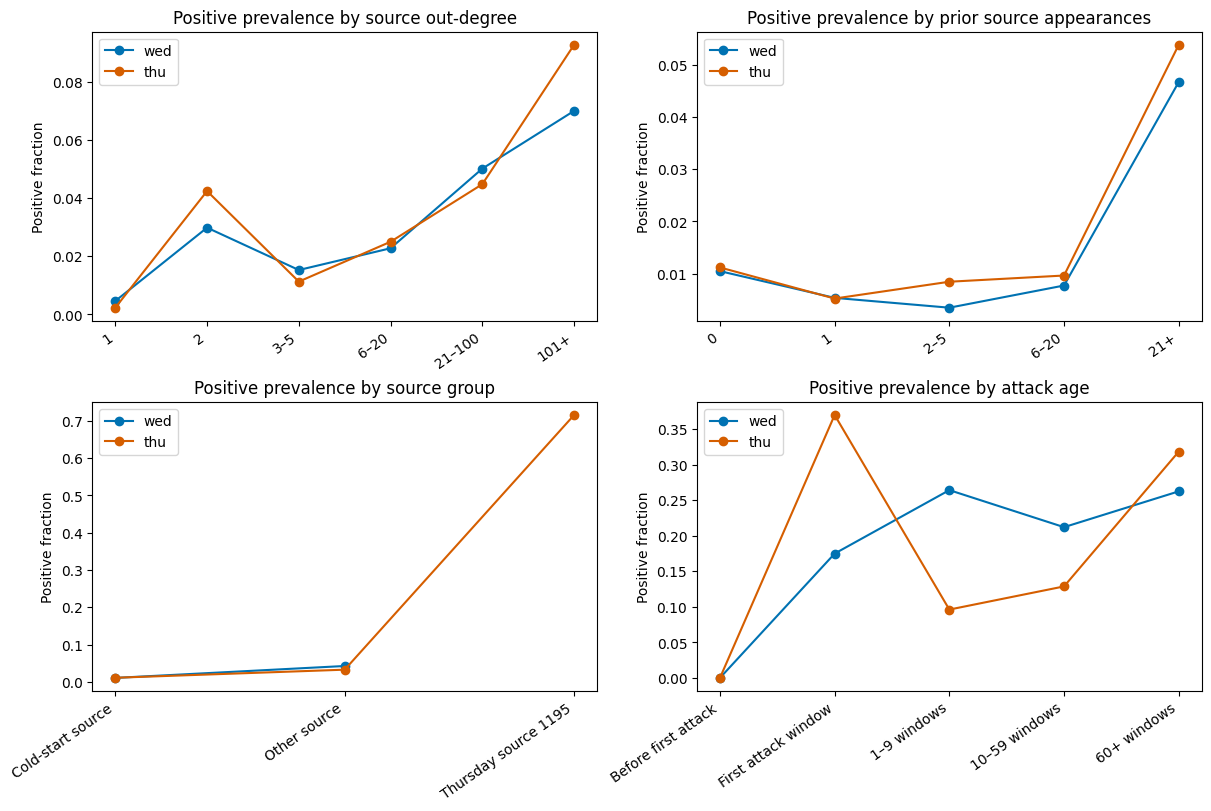

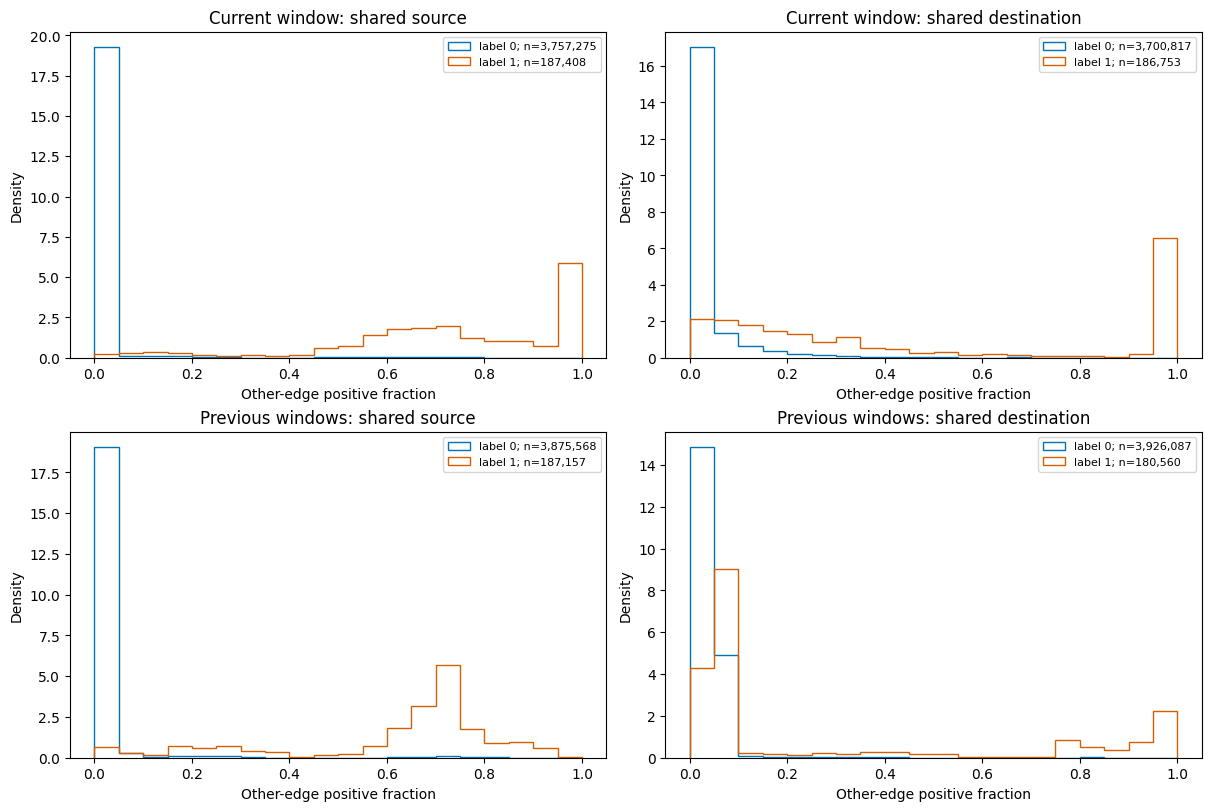

Thursday source 1195: 51625 flows; 36934 positive


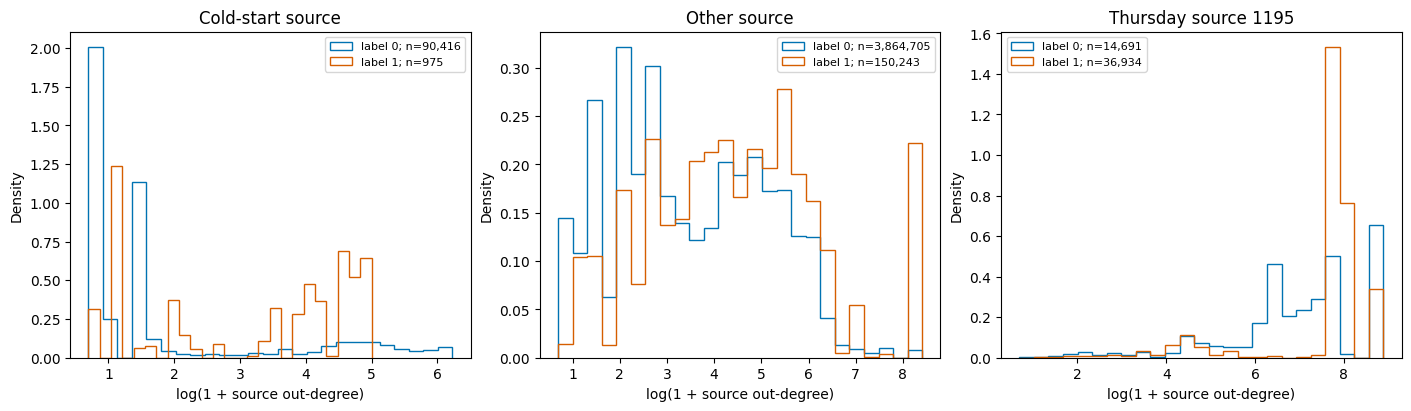

In [6]:
PLOT_DIR = RUN_DIR / 'plots'
PLOT_DIR.mkdir(exist_ok=True)
PLOT_COLUMNS = ['day', 'split', 'window_id', 'source_gid', 'label',
                'snapshot_src_out_degree', 'snapshot_src_component_size',
                'snapshot_only_target_context', 'prior_window_src_appearances',
                'prior_window_no_incident_edges', 'attack_age_windows',
                'diag_current_shared_src_positive_fraction',
                'diag_current_shared_dst_positive_fraction',
                'diag_past_shared_src_positive_fraction',
                'diag_past_shared_dst_positive_fraction',
                'causal_join_status']
plot_parts = []
for day in ('wed', 'thu'):
    for path in sorted((PER_FLOW_DIR / day).glob('part_*.parquet')):
        available = pq.ParquetFile(path).schema.names
        columns = [c for c in PLOT_COLUMNS if c in available]
        extra = ['causal_no_prior_incident_edges'] if 'causal_no_prior_incident_edges' in available else []
        plot_parts.append(pd.read_parquet(path, columns=columns + extra))
plot_data = pd.concat(plot_parts, ignore_index=True)
plot_data['source_group'] = np.where(
    (plot_data.day == 'thu') & (plot_data.source_gid == 1195),
    'Thursday source 1195',
    np.where(plot_data.prior_window_src_appearances == 0, 'Cold-start source', 'Other source'))
plot_data['degree_bin'] = pd.cut(plot_data.snapshot_src_out_degree,
                                  bins=[0, 1, 2, 5, 20, 100, np.inf],
                                  labels=['1', '2', '3–5', '6–20', '21–100', '101+'])
plot_data['history_bin'] = pd.cut(plot_data.prior_window_src_appearances,
                                   bins=[-1, 0, 1, 5, 20, np.inf],
                                   labels=['0', '1', '2–5', '6–20', '21+'])
plot_data['attack_age_bin'] = pd.cut(plot_data.attack_age_windows,
                                      bins=[-np.inf, -1, 0, 9, 59, np.inf],
                                      labels=['Before first attack', 'First attack window',
                                              '1–9 windows', '10–59 windows', '60+ windows'])
summary_rows = []
for day in ('wed', 'thu'):
    part = plot_data.loc[plot_data.day == day]
    for label in (0, 1):
        sub = part.loc[part.label == label]
        record = {'day': day, 'label': label, 'flows': len(sub),
                  'snapshot_only_target_share': float(sub.snapshot_only_target_context.mean()),
                  'no_prior_start_window_incident_share': float(sub.prior_window_no_incident_edges.mean())}
        if 'causal_no_prior_incident_edges' in sub:
            record['no_prior_completed_incident_share'] = float(sub.causal_no_prior_incident_edges.mean())
        summary_rows.append(record)
summary = pd.DataFrame(summary_rows)
summary.to_csv(RUN_DIR / 'core_diagnostic_shares.csv', index=False)
display(summary)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for ax, variable, title in [
    (axes[0, 0], 'degree_bin', 'Positive prevalence by source out-degree'),
    (axes[0, 1], 'history_bin', 'Positive prevalence by prior source appearances'),
    (axes[1, 0], 'source_group', 'Positive prevalence by source group'),
    (axes[1, 1], 'attack_age_bin', 'Positive prevalence by attack age'),
]:
    grouped = plot_data.groupby(['day', variable], observed=True).label.agg(['mean', 'size']).reset_index()
    for day, color in [('wed', '#0072B2'), ('thu', '#D55E00')]:
        sub = grouped.loc[grouped.day == day]
        ax.plot(range(len(sub)), sub['mean'], marker='o', label=day, color=color)
        ax.set_xticks(range(len(sub)), sub[variable].astype(str), rotation=35, ha='right')
    ax.set_title(title)
    ax.set_ylabel('Positive fraction')
    ax.legend()
fig.savefig(PLOT_DIR / 'degree_history_source_attack_age.png', dpi=180)
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for ax, column, title in zip(axes.flat,
    ['diag_current_shared_src_positive_fraction', 'diag_current_shared_dst_positive_fraction',
     'diag_past_shared_src_positive_fraction', 'diag_past_shared_dst_positive_fraction'],
    ['Current window: shared source', 'Current window: shared destination',
     'Previous windows: shared source', 'Previous windows: shared destination']):
    for label, color in [(0, '#0072B2'), (1, '#D55E00')]:
        vals = plot_data.loc[plot_data.label == label, column].dropna().to_numpy()
        if len(vals):
            ax.hist(vals, bins=np.linspace(0, 1, 21), density=True, histtype='step',
                    label=f'label {label}; n={len(vals):,}', color=color)
    ax.set_title(title)
    ax.set_xlabel('Other-edge positive fraction')
    ax.set_ylabel('Density')
    ax.legend(fontsize=8)
fig.savefig(PLOT_DIR / 'neighbor_label_mix.png', dpi=180)
plt.show()

source_summary = (plot_data.groupby(['day', 'source_gid'])
                  .agg(flows=('label', 'size'), positives=('label', 'sum'),
                       median_degree=('snapshot_src_out_degree', 'median'),
                       no_prior_window_share=('prior_window_no_incident_edges', 'mean'))
                  .reset_index())
source_summary.to_parquet(RUN_DIR / 'source_distributions.parquet', index=False)
source_1195 = plot_data.loc[(plot_data.day == 'thu') & (plot_data.source_gid == 1195)]
print('Thursday source 1195:', len(source_1195), 'flows;',
      int(source_1195.label.sum()), 'positive')
fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
for ax, group_name in zip(axes, ['Cold-start source', 'Other source', 'Thursday source 1195']):
    group = plot_data.loc[plot_data.source_group == group_name]
    for label, color in [(0, '#0072B2'), (1, '#D55E00')]:
        values = np.log1p(group.loc[group.label == label, 'snapshot_src_out_degree'].to_numpy())
        if len(values):
            ax.hist(values, bins=25, density=True, histtype='step', color=color,
                    label=f'label {label}; n={len(values):,}')
    ax.set_title(group_name)
    ax.set_xlabel('log(1 + source out-degree)')
    ax.set_ylabel('Density')
    ax.legend(fontsize=8)
fig.savefig(PLOT_DIR / 'degree_by_label_and_source_group.png', dpi=180)
plt.show()
assert plot_data.diag_current_shared_src_positive_fraction.dropna().between(0, 1).all()
assert plot_data.diag_current_shared_dst_positive_fraction.dropna().between(0, 1).all()
del plot_data, plot_parts, source_1195


## 7. Conditional train/validation baseline

Three fixed feature sets are compared with the same gradient-boosted tree configuration: target attributes; target plus endpoint history; and those features plus label-free neighborhood summaries. The primary comparison is the second versus the third. If both raw joins passed, the primary analysis uses strictly prior completed context. Otherwise it uses prior flow-start windows and is explicitly retrospective. The current-window snapshot metrics and every `diag_*`, `label`, `source_gid`, and attack-age field are excluded from model features. Training is restricted to Wednesday train; validation selects no new feature list or hyperparameters. Test 1 and Thursday Test 2 are frozen exploratory readouts of those fitted models.


In [7]:
ATTR = [f'attr_{k:02d}' for k in range(32)]
OWN_WINDOW = ['prior_window_src_appearances', 'prior_window_dst_appearances',
              'prior_window_src_gap_windows', 'prior_window_dst_gap_windows',
              'prior_window_src_incident_edges', 'prior_window_dst_incident_edges',
              'prior_window_src_out_edges', 'prior_window_dst_in_edges']
NEIGHBOR_WINDOW = ['prior_window_src_distinct_out_peers',
                   'prior_window_dst_distinct_in_peers',
                   'prior_window_src_peer_activity',
                   'prior_window_dst_peer_activity']
OWN_CAUSAL = ['causal_src_in_degree', 'causal_src_out_degree',
              'causal_dst_in_degree', 'causal_dst_out_degree',
              'causal_prior_src_incident_edges', 'causal_prior_dst_incident_edges']
NEIGHBOR_CAUSAL = ['causal_src_distinct_out_peers',
                   'causal_dst_distinct_in_peers',
                   'causal_src_peer_activity', 'causal_dst_peer_activity',
                   'causal_src_component_size', 'causal_dst_component_size',
                   'causal_src_reach_1hop', 'causal_src_reach_2hop',
                   'causal_dst_reach_1hop', 'causal_dst_reach_2hop']
use_causal = all(join_audit[d]['status'] == 'PASS' for d in ('wed', 'thu'))
OWN = OWN_CAUSAL if use_causal else OWN_WINDOW
NEIGHBOR = NEIGHBOR_CAUSAL if use_causal else NEIGHBOR_WINDOW
FEATURE_SETS = {'target_only': ATTR,
                'target_plus_endpoint_history': ATTR + OWN,
                'target_endpoint_plus_neighbors': ATTR + OWN + NEIGHBOR}
assert not any(c.startswith('diag_') for features in FEATURE_SETS.values() for c in features)
assert not any(c in {'label', 'source_gid', 'destination_gid', 'attack_age_windows'}
               for features in FEATURE_SETS.values() for c in features)
print('Model context:', 'strictly prior completed, zero delay' if use_causal
      else 'prior flow-start windows, retrospective')
print('Feature counts:', {k: len(v) for k, v in FEATURE_SETS.items()})

feature_union = list(dict.fromkeys(sum(FEATURE_SETS.values(), [])))

def load_split(day, split):
    frames = []
    for path in sorted((PER_FLOW_DIR / day).glob('part_*.parquet')):
        part = pd.read_parquet(path, columns=['split', 'label', *feature_union])
        selected = part.loc[part.split == split]
        if len(selected):
            frames.append(selected)
    assert frames, (day, split)
    return pd.concat(frames, ignore_index=True)

train = load_split('wed', 'train')
validation = load_split('wed', 'val')
assert train.label.nunique() == 2 and validation.label.nunique() == 2
MAX_TRAIN_ROWS = 500_000
rng = np.random.default_rng(2024)
if len(train) > MAX_TRAIN_ROWS:
    # Fixed stratified sampling for Colab memory. It changes training prevalence;
    # AP is used for ranking, with no probability calibration claim.
    positive = np.flatnonzero(train.label.to_numpy() == 1)
    negative = np.flatnonzero(train.label.to_numpy() == 0)
    keep_positive = min(len(positive), MAX_TRAIN_ROWS // 2)
    selected = np.concatenate([rng.choice(positive, keep_positive, replace=False),
                               rng.choice(negative, MAX_TRAIN_ROWS - keep_positive,
                                          replace=False)])
    train_fit = train.iloc[np.sort(selected)].reset_index(drop=True)
else:
    train_fit = train
print('Fit rows:', len(train_fit), 'positive:', int(train_fit.label.sum()))

models = {}
baseline_rows = []
for name, features in FEATURE_SETS.items():
    assert set(features).issubset(train_fit.columns)
    assert not train_fit[features].isna().any().any()
    model = HistGradientBoostingClassifier(max_iter=100, max_leaf_nodes=15,
                                            max_depth=4, learning_rate=0.07,
                                            l2_regularization=1.0,
                                            random_state=2024)
    model.fit(train_fit[features].to_numpy(dtype=np.float32), train_fit.label.to_numpy())
    models[name] = model
    for split_name, frame in [('train_sample', train_fit), ('validation', validation)]:
        scores = model.predict_proba(frame[features].to_numpy(dtype=np.float32))[:, 1]
        baseline_rows.append({'model': name, 'split': split_name,
                              'context_type': 'causal_prior_completed' if use_causal else 'prior_start_windows',
                              'flows': len(frame), 'positives': int(frame.label.sum()),
                              'prevalence': float(frame.label.mean()),
                              'AP': float(average_precision_score(frame.label, scores))})
baseline_results = pd.DataFrame(baseline_rows)
for day, split in [('wed', 'test'), ('thu', 'test2')]:
    frame = load_split(day, split)
    for name, features in FEATURE_SETS.items():
        scores = models[name].predict_proba(frame[features].to_numpy(dtype=np.float32))[:, 1]
        baseline_results.loc[len(baseline_results)] = {
            'model': name, 'split': split, 'context_type':
            'causal_prior_completed' if use_causal else 'prior_start_windows',
            'flows': len(frame), 'positives': int(frame.label.sum()),
            'prevalence': float(frame.label.mean()),
            'AP': float(average_precision_score(frame.label, scores))}
    del frame
baseline_results.to_csv(RUN_DIR / 'conditional_baseline_ap.csv', index=False)
display(baseline_results)


Model context: strictly prior completed, zero delay
Feature counts: {'target_only': 32, 'target_plus_endpoint_history': 38, 'target_endpoint_plus_neighbors': 48}
Fit rows: 500000 positive: 49564


,model,split,context_type,flows,positives,prevalence,AP
0,target_only,train_sample,causal_prior_completed,500000,49564,0.099128,0.469810
1,target_only,validation,causal_prior_completed,788535,31329,0.039731,0.277012
2,target_plus_endpoint_history,train_sample,causal_prior_completed,500000,49564,0.099128,0.834249
3,target_plus_endpoint_history,validation,causal_prior_completed,788535,31329,0.039731,0.306531
4,target_endpoint_plus_neighbors,train_sample,causal_prior_completed,500000,49564,0.099128,0.920670
5,target_endpoint_plus_neighbors,validation,causal_prior_completed,788535,31329,0.039731,0.392780
6,target_only,test,causal_prior_completed,191679,3434,0.017915,0.073703
7,target_plus_endpoint_history,test,causal_prior_completed,191679,3434,0.017915,0.021555
8,target_endpoint_plus_neighbors,test,causal_prior_completed,191679,3434,0.017915,0.038277
9,target_only,test2,causal_prior_completed,2135957,103825,0.048608,0.461716


## 8. Final checks and manifest

Interpretation: compare neighborhood AP with endpoint-history AP on validation first. Degree and label-mix plots describe information availability, not proof that a GNN can learn it. A Test 2 improvement cannot be called confirmatory because this capture already informed the research plan. If the raw join failed, any claim about usable completed neighbors is deferred to Experiment 5.


In [8]:
manifest = {
    'experiment': 2,
    'created_utc': datetime.now(timezone.utc).isoformat(),
    'preprocessing_reference': PREPROCESSING_REFERENCE,
    'graph_version': GRAPH_VERSION,
    'label': 'original Attack == Infilteration',
    'window_seconds': WINDOW_SECONDS,
    'time_convention': 'complete flow-start snapshot; causal prior uses raw flow end and zero exporter delay',
    'raw_join_audit': join_audit,
    'causal_status': causal_status,
    'baseline_context': 'causal_prior_completed' if use_causal else 'prior_start_windows_retrospective',
    'baseline_feature_sets': FEATURE_SETS,
    'baseline_configuration': {'model': 'HistGradientBoostingClassifier', 'max_iter': 100,
                               'max_leaf_nodes': 15, 'max_depth': 4,
                               'learning_rate': 0.07, 'l2_regularization': 1.0,
                               'random_state': 2024, 'max_train_rows': MAX_TRAIN_ROWS},
    'flow_counts': {f'{day}_{kind}': int(count)
                    for (day, kind), count in per_flow_counts.items()},
    'inputs': {'graph_roots': {'wed': str(WED_ROOT), 'thu': str(THU_ROOT)},
               'raw_csv': {day: str(path) for day, path in RAW_CSV.items()},
               'scaler': str(SCALER_PATH)},
    'outputs': {'per_flow': str(PER_FLOW_DIR),
                'per_window': str(RUN_DIR / 'window_feature_distributions.parquet'),
                'core_shares': str(RUN_DIR / 'core_diagnostic_shares.csv'),
                'baseline_ap': str(RUN_DIR / 'conditional_baseline_ap.csv')},
}
(RUN_DIR / 'manifest.json').write_text(json.dumps(manifest, indent=2, default=str))
print('Saved:', RUN_DIR)


Saved: /content/drive/MyDrive/nids-mitre/results_comparison/graph_neighborhood_audit_v1/run_20261022T142050Z
